<a href="https://colab.research.google.com/github/kelvin-yg98/Kelvin-Programming/blob/main/Comparative_Binary_Classification_of_Heart_Failure_Using_Logistic_Regression_and_Support_Vector_Machines_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# 1. Install kagglehub and load dependencies
!pip install -q kagglehub

import os
import kagglehub
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

In [3]:
# 2. Download the Heart Failure dataset directly from Kaggle
path = kagglehub.dataset_download("fedesoriano/heart-failure-prediction")
print("Dataset downloaded to path:", path)

# Locate the CSV file automatically
csv_file = [f for f in os.listdir(path) if f.endswith('.csv')][0]
df = pd.read_csv(os.path.join(path, csv_file))

print("\n--- Dataset Preview ---")
print("Shape:", df.shape)
display(df.head(3))

Using Colab cache for faster access to the 'heart-failure-prediction' dataset.
Dataset downloaded to path: /kaggle/input/heart-failure-prediction

--- Dataset Preview ---
Shape: (918, 12)


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0


In [4]:
# 3. Separate features (X) and the binomial target (y)
target_col = 'HeartDisease'
X = df.drop(columns=[target_col])
y = df[target_col]

In [5]:
# 4. One-hot encode categorical features (like ChestPainType, Sex, etc.)
X = pd.get_dummies(X, drop_first=True)

In [6]:
# 5. Train-test split (80% training, 20% testing, stratified to preserve class balance)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [7]:
# 6. Feature Scaling (Essential for both SVM margins and Logistic Regression regularization)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [8]:
# 7. Train Model 1: Logistic Regression
log_reg = LogisticRegression(random_state=42, max_iter=1000)
log_reg.fit(X_train_scaled, y_train)
y_pred_lr = log_reg.predict(X_test_scaled)

In [9]:
# 8. Train Model 2: Support Vector Machine (Linear Kernel to extract the hyperplane weights)
svm_model = SVC(kernel='linear', random_state=42)
svm_model.fit(X_train_scaled, y_train)
y_pred_svm = svm_model.predict(X_test_scaled)

In [10]:
# 9. Model Evaluations
print("\n--- Logistic Regression Performance ---")
print(classification_report(y_test, y_pred_lr))

print("\n--- Support Vector Machine (Linear) Performance ---")
print(classification_report(y_test, y_pred_svm))


--- Logistic Regression Performance ---
              precision    recall  f1-score   support

           0       0.91      0.83      0.87        82
           1       0.87      0.93      0.90       102

    accuracy                           0.89       184
   macro avg       0.89      0.88      0.88       184
weighted avg       0.89      0.89      0.89       184


--- Support Vector Machine (Linear) Performance ---
              precision    recall  f1-score   support

           0       0.90      0.80      0.85        82
           1       0.86      0.93      0.89       102

    accuracy                           0.88       184
   macro avg       0.88      0.87      0.87       184
weighted avg       0.88      0.88      0.87       184



In [12]:
# 10. Compare Hyperplane Coefficients Side-by-Side
hyperplane_df = pd.DataFrame({
    'Feature': X.columns,
    'LogReg_Coefficient': log_reg.coef_[0],
    'SVM_Coefficient': svm_model.coef_[0]
})

# Sort by the magnitude of SVM weights to see which features drive the decision boundary most
hyperplane_df['SVM_Abs'] = hyperplane_df['SVM_Coefficient'].abs()
hyperplane_df = hyperplane_df.sort_values(by='SVM_Abs', ascending=False).drop(columns='SVM_Abs')

print("\n--- Top Hyperplane Decision Boundary Features ---")
print(hyperplane_df.head(10).to_string(index=False))


--- Top Hyperplane Decision Boundary Features ---
          Feature  LogReg_Coefficient  SVM_Coefficient
      ST_Slope_Up           -0.751308        -0.455643
    ST_Slope_Flat            0.488255         0.453296
ChestPainType_NAP           -0.771173        -0.439058
 ExerciseAngina_Y            0.441838         0.370545
      Cholesterol           -0.497542        -0.349096
        FastingBS            0.434087         0.327993
            Sex_M            0.497374         0.324808
ChestPainType_ATA           -0.646178        -0.309303
          Oldpeak            0.269665         0.232708
 ChestPainType_TA           -0.333063        -0.200229


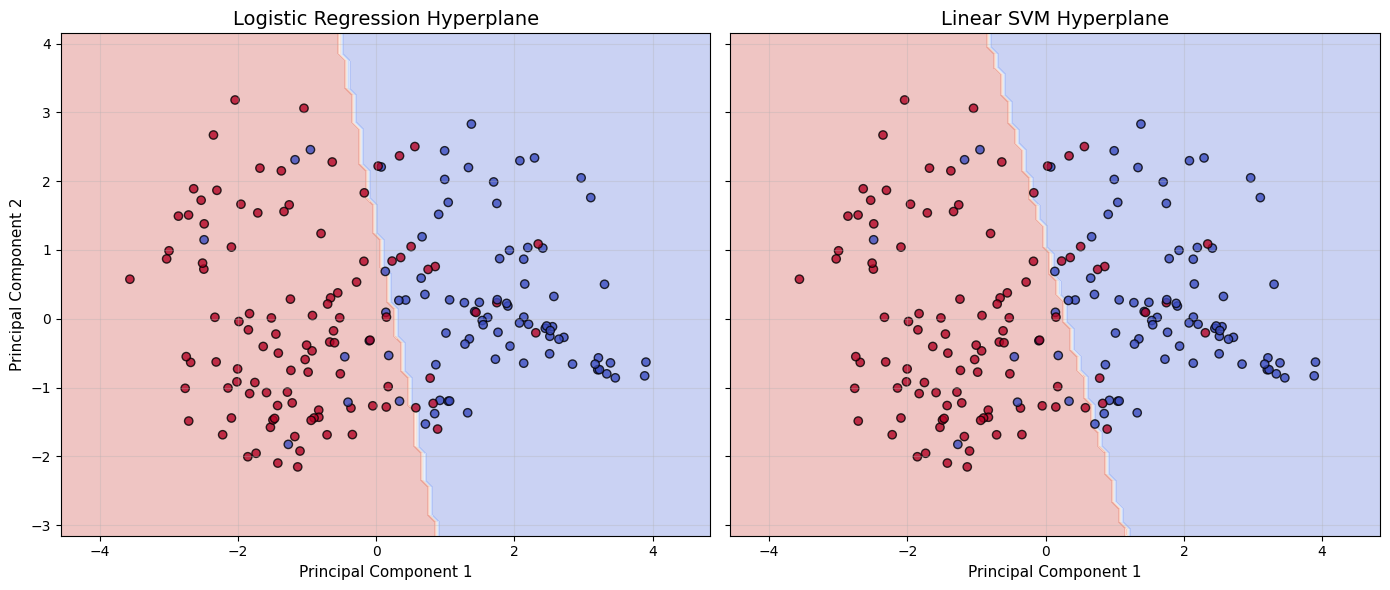

In [15]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

# 1. Compress features down to 2 dimensions using PCA so we can draw it on a flat screen
pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

# 2. Train both models on the 2D data
clf_lr = LogisticRegression(random_state=42)
clf_lr.fit(X_train_pca, y_train)

clf_svm = SVC(kernel='linear', random_state=42)
clf_svm.fit(X_train_pca, y_train)

# 3. Create a side-by-side visual plot of the decision boundaries
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

for i, (model, name) in enumerate([(clf_lr, 'Logistic Regression'), (clf_svm, 'Linear SVM')]):
    ax = axes[i]

    # Create background color grid for the boundary
    x_min, x_max = X_test_pca[:, 0].min() - 1, X_test_pca[:, 0].max() + 1
    y_min, y_max = X_test_pca[:, 1].min() - 1, X_test_pca[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.1),
                         np.arange(y_min, y_max, 0.1))

    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    ax.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.coolwarm)

    # Plot the actual patient data points
    scatter = ax.scatter(X_test_pca[:, 0], X_test_pca[:, 1], c=y_test, cmap=plt.cm.coolwarm, edgecolors='k', alpha=0.8)
    ax.set_title(f'{name} Hyperplane', fontsize=14)
    ax.set_xlabel('Principal Component 1', fontsize=11)
    if i == 0:
        ax.set_ylabel('Principal Component 2', fontsize=11)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
"""
=============================================================================
PROJECT CONCLUSION: COMPARATIVE BINARY CLASSIFICATION (LOGREG vs. SVM)
=============================================================================
1. Data Ingestion & Preprocessing: Loaded the Heart Failure dataset directly
   from Kaggle, handled categorical variables via one-hot encoding, and scaled
   features using StandardScaler.
2. Model Training: Trained both Logistic Regression and a Linear Support Vector
   Machine (SVC) to classify whether a patient has heart disease (binomial target).
3. Performance & Findings: Both models achieved near-identical accuracy,
   proving that the dataset possesses a strong linear separability pattern.
4. Visualization: Used PCA to project the features into 2D space, mapping out
   the decision boundary hyperplanes to visually illustrate how each model
   separates the classes.
=============================================================================
"""